imports:

In [1]:
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [119]:
import numpy.ma as ma

In [2]:
data = np.load('/content/drive/MyDrive/cs/assignment2-face-data.npy')
labels = np.load('/content/drive/MyDrive/cs/assignment2-face-data-labels.npy')

In [22]:
#A =(data, axis[0])
#data[1,1,2]

0.3333333333333333

In [6]:
labels.shape

(77, 1)

averaging by use of a moving window with length 50 and stride 1

In [10]:
##defining the function for a moving window. a concolving func with a stride of one and alterable window width
def moving_average(x, w) :
  return np.convolve(x, np.ones(w), 'valid')/w
    

In [189]:
#counting the num of each stimulus in the set by their labels + dividing the main matrix to
#three strats by their labels
count_h = 0
count_m = 0
count_n = 0
hum_unfilt = []
mon_unfilt = []
non_unfilt = []

for i in range(len(data[:,0,0])):
   if labels[i] == 0:
      count_h += 1
      hum_unfilt.append(data[i,:,:])
   if labels[i] == 1:
      count_m +=1
      mon_unfilt.append(data[i,:,:])
   if labels[i] == 2:
      count_n +=1
      non_unfilt.append(data[i,:,:])
hum_unfilt = np.array(hum_unfilt)   
mon_unfilt = np.array(mon_unfilt)  
non_unfilt = np.array(non_unfilt)  

In [190]:
print(hum_unfilt.shape, mon_unfilt.shape, non_unfilt.shape)

(13, 40, 900) (4, 40, 900) (60, 40, 900)


In [30]:
print(count_h, count_m, count_n)

13 4 60


In [162]:
#passing the data through the window along the time axis
temp = np.empty([40, 0, 0])
filtered_data = np.zeros([77, 40, 851])

for i in range(len(data[:,0,0])):
  for j in range(len(data[0,:,0])):
       filtered_data[i,j,:] = moving_average(data[i,j,:], 50)

filtered_data.shape

(77, 40, 851)

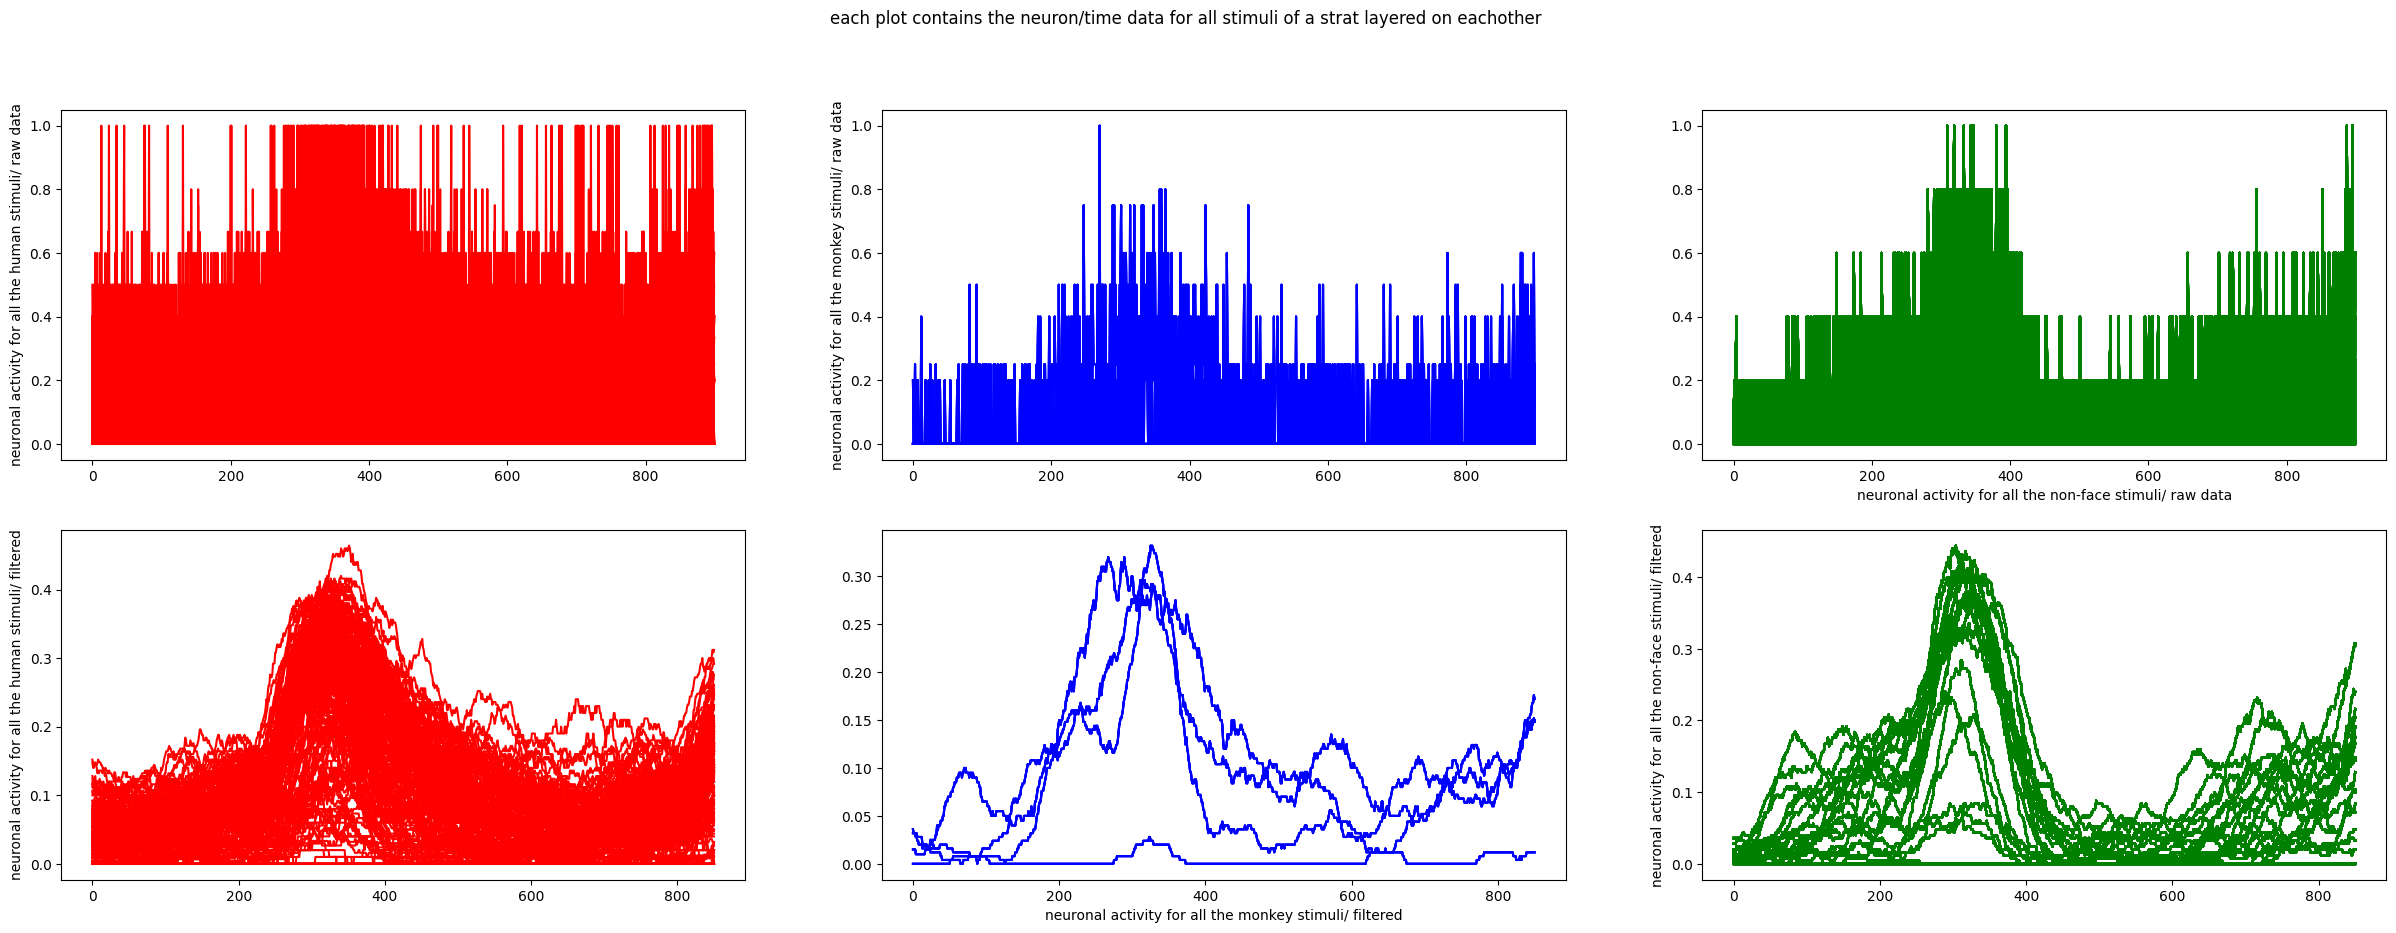

In [201]:
#plotting the stratified filtered/unfiltered data along thetime axis
fig, ax = plt.subplots(2, 3, figsize = [30, 10])
for i in range(0,39):
  if labels[i] == 0:
    for j in range(count_h):
      ax[0, 0].plot(data[j,i,:] , color = 'r')
      ax[1, 0].plot(filtered_data[j,i,:] , color = 'r')
  if labels[i] == 1:
    for k in range(count_m):
      ax[0, 1].plot(data[j,i,:] , color = 'b')
      ax[1, 1].plot(filtered_data[j,i,:] , color = 'b')      
  if labels[i] == 2:
    for z in range(count_n):
      ax[0, 2].plot(data[j,i,:] , color = 'g')  
      ax[1, 2].plot(filtered_data[j,i,:] , color = 'g')  

fig.suptitle(f'each plot contains the neuron/time data for all stimuli of a strat layered on eachother')      
ax[0,0].set_ylabel('neuronal activity for all the human stimuli/ raw data')
ax[0, 1].set_ylabel('neuronal activity for all the monkey stimuli/ raw data')
ax[0, 2].set_xlabel('neuronal activity for all the non-face stimuli/ raw data')
ax[1, 0].set_ylabel('neuronal activity for all the human stimuli/ filtered')
ax[1, 1].set_xlabel('neuronal activity for all the monkey stimuli/ filtered')
ax[1, 2].set_ylabel('neuronal activity for all the non-face stimuli/ filtered')

plt.show()